# Werkspoorbrug (Amsterdam-Rhine Canal)

## Working file


## Importing Required Packages

Below, the required packages are imported. To run this notebook successfully, your environment must include the required dependencies. The virtual environment provided in MUDE, called **`mude-base`**, is sufficient for this purpose.

In addition, several plotting settings are defined, and the local optimisation code is imported. It is important that the provided zip file is extracted in its entirety, as the structure of the directory is required for the imports to work correctly.

The local module `genetic_algorithm_pfm` is imported using a **relative import**, which depends on the directory structure of the project. When the notebook is executed within the provided directory structure, this will work as intended. However, running the notebook outside of this directory will result in the following error: `ModuleNotFoundError: No module named 'genetic_algorithm_pfm'`

In [39]:
# Import libraries
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import pchip_interpolate
from scipy.optimize import minimize

# Define default plotting parameters
plt.rcParams['font.size'] = '10'
plt.rcParams['savefig.dpi'] = 300

# Import local module for genetic algorithm
from genetic_algorithm_pfm import GeneticAlgorithm

## Design Variables and Bounds

The design constraints for the Werkspoorburg.

| Variable | Description | Unit | Type |
|----------|-------------|------|------|
| `x1` | Clearance height | m | Continuous |
| `x2` | Span | m | Continuous |
| `x3` | Slab thickness | m | Continuous |
| `x4` | Bridge width | m | Continuous |
| `x5` | Bridge height | m | Continuous |

**Note:** In the code, design variables are defined only by their type (discrete or continuous) and their bounds — *not* by their physical meaning. Before implementing, it is good practice to write down your choice of design variables on paper, including their units and expected ranges. This helps avoid errors and builds physical intuition for the problem.

`X_irl` contains a reference design based on a real-world installation, which will later be used for comparison against the optimised solutions.

In [40]:
# Define the names of variables for later use in plotting and analysis
design_variables = (
    ('CLH', 'Clearance height', 'm'),
    ('SPN', 'Span', 'm'),
    ('Tb', 'Thickness slab', 'm'),
    ('Wb', 'Width', 'm'),
    ('Ha', 'Height of arch', 'm')
)

# Set bounds for all variables
b1 = [3, 20]     # x1
b2 = [50, 300]   # x2
b3 = [0.2, 2]    # x3
b4 = [5, 25]     # x4
b5 = [12, 60]     # x5
bounds = [b1, b2, b3, b4, b5]

X_irl = [9.1, 176, 1, 5.5, 28]  # Reference: Bert Swartbrug
plot_irl = True

print(design_variables)
print(bounds)

(('CLH', 'Clearance height', 'm'), ('SPN', 'Span', 'm'), ('Tb', 'Thickness slab', 'm'), ('Wb', 'Width', 'm'), ('Ha', 'Height of arch', 'm'))
[[3, 20], [50, 300], [0.2, 2], [5, 25], [12, 60]]


## Constraints

Constraints ensure that all solutions remain physically feasible.

Each *constraint function* must be expressed as an algebraic expression of the form:

$$g(\mathbf{x}) \leq 0 \quad \text{(feasible)}$$

> **Important:** The constraint function should return only the value of $g(\mathbf{x})$ — do *not* encode the inequality inside the function.

In [41]:
def constraint_1(variables):
    CLH = variables[:, 0]
    min_height = 2.75
    return min_height - CLH

def constraint_2(variables):
    SPN = variables[:, 1]
    min_span = 120
    return min_span - SPN

def constraint_3(variables):
    Tb = variables[:, 2]
    min_Tb = 0.3
    return min_Tb - Tb

def constraint_4(variables):
    Wb = variables[:, 3]
    min_Wb = 5
    return min_Wb - Wb

cons = [['ineq', constraint_1], ['ineq', constraint_2], ['ineq', constraint_3], ['ineq', constraint_4]]

## Objective Functions

| Stakeholder | Objective | Unit |
|-------------|-----------|------|
| Government | Construction cost | mil $ |
| Nature organisations | Carbon emissions | tonnes |
| Citizens | Maintenance | days |
| Companies | Capacity | Trains/Ships per hour |

In [42]:
def objective_function_1(x1, x2, x3, x4, x5):
    cons1 = 2.85
    cons2 = 1000
    volume = x2 * x3 * x4
    cons3 = x2 * (1 + (8 / 3 * (x5 / x2)**2) - (32 / 5 * (x5 / x2)**4))
    cons4 = 40000
    cons5 = 0.6
    cons6 = 0.5
    cons7 = 10000000
    return ((cons1 * cons2 * volume + cons3 * cons5 * x4 * cons4) * cons6 * x1 + cons7) / 1000000

def objective_function_2(x1, x2, x3, x4, x5):
    const1 = x2 * x3 * x4
    const2 = x2 * (1 + (8 / 3 * (x5 / x2)**2) - (32 / 5 * (x5 / x2)**4)) * 0.1 * x4 * 0.1 * x4
    const3 = 0.35
    const4 = 9
    const5 = 2000
    return const1 * const3 + const2 * const4 + const5

def objective_function_3(x1, x2, x3, x4, x5):
    const1 = 1 / 50
    const2 = 2 / 50
    const3 = x2 * (1 + (8 / 3 * (x5 / x2)**2) - (32 / 5 * (x5 / x2)**4))
    const4 = 1 / 100
    const5 = 1 / 50
    const6 = 10 / x4
    return (const1 * x2 + const2 * const3) + 0.5 * (const4 * x2 + const5 * const3) * (const6)**2

def objective_function_4(x1, x2, x3, x4, x5):
    const1 = (x4 - 2) / 3
    const2 = 12
    return const1 * const2 + (x2/150)**2 * 20

objectives = [
    (objective_function_1, "Cost", "mil $", "Government"),
    (objective_function_2, "Carbon Emission", "tonnes", "Environmental Organizations"),
    (objective_function_3, "Maintenance", "no. of days", "Citizens"),
    (objective_function_4, "Capacity", "Trains/Ships per hour", "Company"),
]

In [43]:
objective_minmax = {}
midpoints = [np.mean(b) for b in bounds]

for idx, (obj_func, name, unit, stakeholder) in enumerate(objectives):
    wrapped = lambda x, sign=1: sign * obj_func(*x)
    min_val = minimize(wrapped, x0=midpoints, bounds=bounds, method='L-BFGS-B').fun
    max_val = -minimize(lambda x: wrapped(x, sign=-1), x0=midpoints, bounds=bounds, method='L-BFGS-B').fun
    objective_minmax[name] = min_val, max_val
    print(f"  Objective {idx+1}  :    min = {min_val:>15,.1f}  {unit:<12}    max = {max_val:>15,.1f}  {unit}")

  Objective 1  :    min =            20.4  mil $           max =         2,411.1  mil $
  Objective 2  :    min =         2,144.9  tonnes          max =        25,752.2  tonnes
  Objective 3  :    min =             3.4  no. of days     max =            38.3  no. of days
  Objective 4  :    min =            14.2  Trains/Ships per hour    max =           172.0  Trains/Ships per hour


In [44]:
weights_before = [0.25, 0.25, 0.25, 0.25]
weights_after  = [0.20, 0.15, 0.50, 0.15]

weights = weights_after
assert np.isclose(sum(weights), 1.0), f"Weights must sum to 1, got {sum(weights)}"

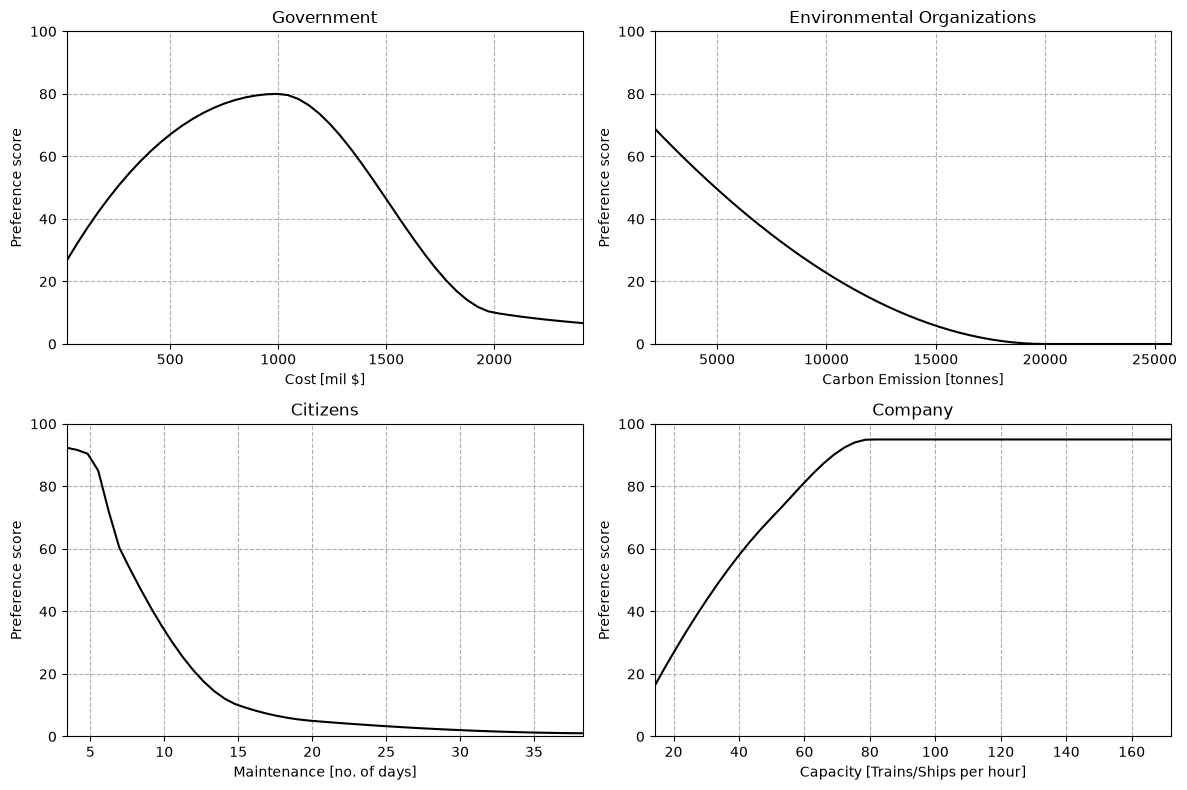

In [45]:
prefs_before = [
    [[50, 1000, 2000, 3000, 3500], [30, 80, 10, 4, 2]],
    [[0, 2000, 20000, 21000], [100, 70, 0, 0]],
    [[0, 1, 5, 7, 15, 20,40], [100, 95, 90, 60, 10, 5,1]],
    [[6, 50, 80, 150, 200, 250], [0, 70, 95, 95, 95, 95]]
]

prefs = prefs_before

obj_vals_list = []
for _, name, _, _ in objectives:
    obj_vals = np.linspace(*objective_minmax[name])
    obj_vals_list.append(obj_vals)

pref_vals_list = []
for pref, obj_vals in zip(prefs, obj_vals_list):
    pref_vals = pchip_interpolate(pref[0], pref[1], obj_vals)
    pref_vals_list.append(pref_vals)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (obj_vals, p_vals), (_, name, unit, stakeholder) in zip(axes.flat, zip(obj_vals_list, pref_vals_list), objectives):
    ax.plot(obj_vals, p_vals, color='black')
    ax.set_xlim(min(obj_vals), max(obj_vals))
    ax.set_ylim(0, 100)
    ax.set_title(stakeholder)
    ax.set_xlabel(f'{name} [{unit}]')
    ax.set_ylabel('Preference score')
    ax.grid(linestyle='--')

fig.tight_layout()
plt.show()

def pref_func_1(x1, x2, x3, x4, x5):
    cost = objective_function_1(x1, x2, x3, x4, x5)
    return pchip_interpolate(prefs[0][0], prefs[0][1], cost)

def pref_func_2(x1, x2, x3, x4, x5):
    ride = objective_function_2(x1, x2, x3, x4, x5)
    return pchip_interpolate(prefs[1][0], prefs[1][1], ride)

def pref_func_3(x1, x2, x3, x4, x5):
    sed = objective_function_3(x1, x2, x3, x4, x5)
    return pchip_interpolate(prefs[2][0], prefs[2][1], sed)

def pref_func_4(x1, x2, x3, x4, x5):
    safe = objective_function_4(x1, x2, x3, x4, x5)
    return pchip_interpolate(prefs[3][0], prefs[3][1], safe)

pref_funcs = [pref_func_1, pref_func_2, pref_func_3, pref_func_4]

def objective(variables):
    x1 = variables[:, 0]
    x2 = variables[:, 1]
    x3 = variables[:, 2]
    x4 = variables[:, 3]
    x5 = variables[:, 4]

    p_1 = pref_func_1(x1, x2, x3, x4, x5)
    p_2 = pref_func_2(x1, x2, x3, x4, x5)
    p_3 = pref_func_3(x1, x2, x3, x4, x5)
    p_4 = pref_func_4(x1, x2, x3, x4, x5)

    return weights, [p_1, p_2, p_3, p_4]


Run GA with minmax
The type of aggregation is set to minmax
Generation   Best score   Mean             Max stall    Diversity    Number of non-feasible results
0            25.5049      81000030.3621    0            0.003        150         
1            23.7495      15000027.3362    0            0.075        29          
2            23.1273      2500025.7291     0            0.084        4           
3            23.1079      4000024.2773     0            0.178        7           
4            23.0327      4500023.477      0            0.186        8           
5            23.0154      8000022.9019     0            0.188        15          
6            23.0154      5500023.1643     1            0.189        10          
7            23.0154      5500022.8924     2            0.191        10          
8            23.0154      7500022.844      3            0.188        14          
9            23.0154      4500023.0019     4            0.19         8           
10           23.015

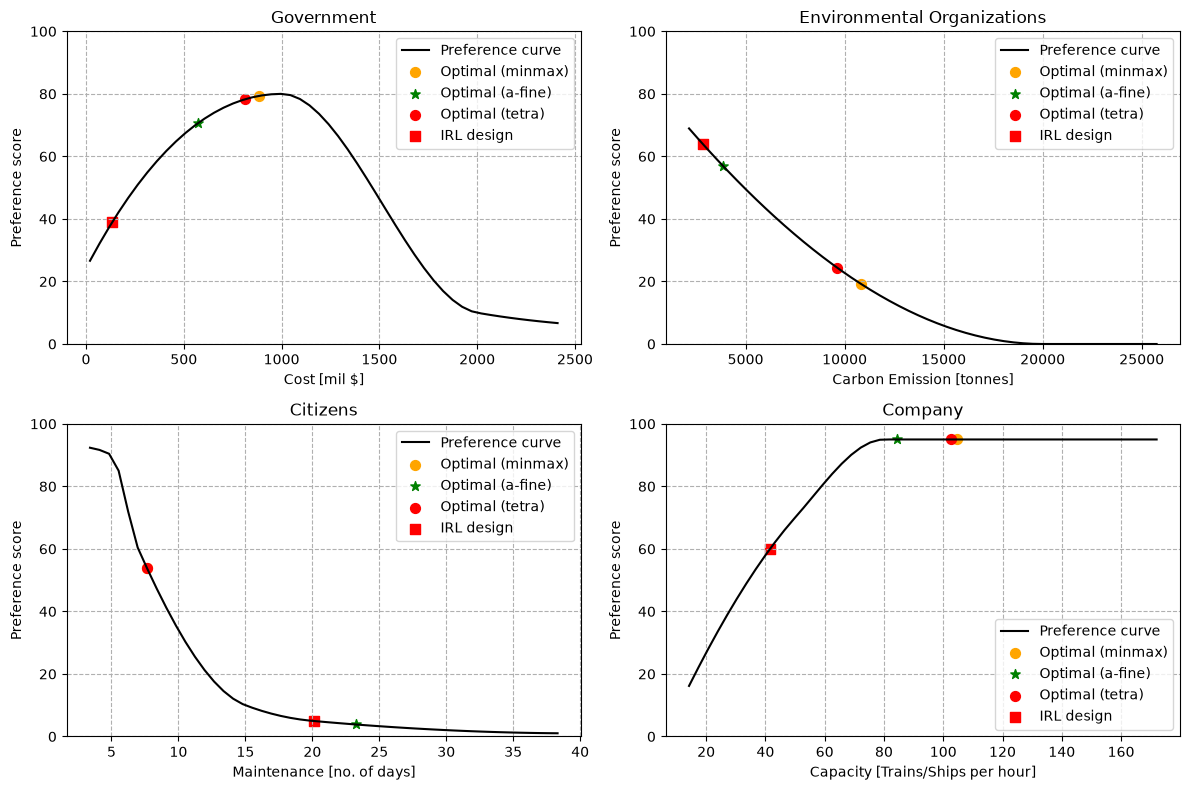

In [46]:
paradigm = ['minmax', 'a-fine', 'tetra']
markers  = ['o', '*', 'o']
colours  = ['orange', 'green', 'red']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, o_vals, p_vals, (_, name, unit, stakeholder) in zip(axes.flat, obj_vals_list, pref_vals_list, objectives):
    ax.plot(o_vals, p_vals, color='black', label='Preference curve')
    ax.set_ylim(0, 100)
    ax.set_title(stakeholder)
    ax.set_xlabel(f'{name} [{unit}]')
    ax.set_ylabel('Preference score')
    ax.grid(linestyle='--')

for i in range(len(paradigm)):
    options = {
        'n_bits': 8,
        'n_iter': 400,
        'n_pop': 500,
        'r_cross': 0.8,
        'max_stall': 16,
        'aggregation': paradigm[i],
        'var_type': 'real'
    }

    print(f'\nRun GA with {paradigm[i]}')
    ga = GeneticAlgorithm(objective=objective, constraints=cons, bounds=bounds, options=options)
    _, optimal_design_var, _ = ga.run()

    print(f'Optimal design variable values using {paradigm[i]}:')
    for opt_var, (xi, name, unit) in zip(optimal_design_var, design_variables):
        print(f'  {xi} : {name:<25} = {opt_var:>10.2f} {unit}')

    print(f'Optimal objective results and stakeholder preference using {paradigm[i]}:')
    for j, (ax, (obj_func, name, unit, stakeholder)) in enumerate(zip(axes.flat, objectives)):
        obj_value = obj_func(*optimal_design_var)
        pref_score = pref_funcs[j](*optimal_design_var)
        print(f'  {name:<20} = {obj_value:>15,.2f} {unit:<10} -> {stakeholder:<20} pref: {pref_score:>6.2f}')
        ax.scatter(obj_value, pref_score, color=colours[i], marker=markers[i], s=50, label=f'Optimal ({paradigm[i]})')

if plot_irl:
    irl_obj_values = [obj_func(*X_irl) for obj_func, _, _, _ in objectives]
    irl_pref_scores = [pref_funcs[j](*X_irl) for j in range(len(objectives))]
    for j, ax in enumerate(axes.flat[:4]):
        ax.scatter(irl_obj_values[j], irl_pref_scores[j], color='red', marker='s', s=50, label='IRL design')

for ax in axes.flat:
    ax.legend(fontsize=10)

fig.tight_layout()
plt.show()